In [1]:
#Shishir Khanal
#Aug 26, 2026
#Actor Critic Algorithm for Lunar lander

In [2]:
import numpy as np
import os
import torch as T
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import gym
import matplotlib.pyplot as plt

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [3]:
#Ornstein-Uhlenbeck Action Noise
#Model statistical motion of a Brownian Particle (like damped random walk, curent state depends on prev state)
#Source: OpenAI Baselines Repository

class OUActionNoise():
    def __init__(self, mu, sigma=0.15, theta=0.2, dt=1e-2, x0=None):
        self.theta = theta
        self.mu = mu
        self.sigma = sigma
        self.dt = dt
        self.x0 = x0
        self.reset()

    def __call__(self):
        x = self.x_prev + self.theta * (self.mu - self.x_prev) + self.dt + self.sigma * np.sqrt(self.dt) * np.random.normal(size = self.mu.shape)
        self.x_prev = x
        return x

    def reset(self):
        self.x_prev = self.x0 if self.x0 is not None else np.zeros_like(self.mu)

In [4]:
#Replay buffer: Fixed size, overwrites early memories with new ones
class ReplayBuffer():
    def __init__(self, max_size, input_shape, n_actions):
        self.mem_size = max_size
        self.mem_cntr = 0
        self.state_memory = np.zeros((self.mem_size, *input_shape)) #'*' means unpack list of elements
        self.new_state_memory = np.zeros((self.mem_size, *input_shape))
        self.action_memory = np.zeros((self.mem_size, n_actions)) #For lunar lander 4 element
        self.reward_memory = np.zeros(self.mem_size)
        self.terminal_memory = np.zeros(self.mem_size, dtype=bool) #mask for setting critique values for new states to 0

    def store_transition(self, state, action, reward, state_, done):
        index = self.mem_cntr % self.mem_size
        self.state_memory[index] = state
        self.action_memory[index] = action
        self.reward_memory[index] = reward
        self.new_state_memory[index] = state_
        self.terminal_memory[index] = done
        self.mem_cntr += 1

    def sample_buffer(self, batch_size):
        max_mem = min(self.mem_cntr, self.mem_size)
        batch = np.random.choice(max_mem, batch_size)
        states = self.state_memory[batch] 
        actions = self.action_memory[batch] 
        rewards = self.reward_memory[batch]
        states_ = self.new_state_memory[batch]
        dones = self.terminal_memory[batch]

        return states, actions, rewards, states_, dones 

In [5]:
#Deep NN Class for Critic
#2 Hidden Layers: 400, 300; ReLU Activation
#Adam Optimizer, lr 10^-3, weight decay 0.01
#Output layer Random weights, between interval: [-3x10^-3, 3x10^-3]
#Other layers random weights, between interval: [-1/sqrt(f), 1/sqrt(f)]
#Batch Norm prior to action input (Hidden layer 2nd)

class CriticNetwork(nn.Module):
    def __init__(self, beta, input_dims, fc1_dims, fc2_dims, n_actions, name, chkpt_dir='tmp/ddpg'):
        super(CriticNetwork, self).__init__()
        self.input_dims = input_dims
        self.fc1_dims = fc1_dims
        self.fc2_dims = fc2_dims
        self.n_actions = n_actions
        self.name = name
        self.checkpoint_dir = chkpt_dir
        self.checkpoint_file = os.path.join(self.checkpoint_dir, name + '_ddpg')
        self.fc1 = nn.Linear(*self.input_dims, self.fc1_dims)
        self.fc2 = nn.Linear(self.fc1_dims, self.fc2_dims)

        self.bn1 = nn.LayerNorm(self.fc1_dims)
        self.bn2 = nn.LayerNorm(self.fc2_dims)

        self.action_value = nn.Linear(self.n_actions, self.fc2_dims)
        self.q = nn.Linear(self.fc2_dims, 1)

        f1 = 1./np.sqrt(self.fc1.weight.data.size()[0])
        self.fc1.weight.data.uniform_(-f1, f1)
        self.fc1.bias.data.uniform_(-f1, f1)

        f2 = 1./np.sqrt(self.fc2.weight.data.size()[0])
        self.fc2.weight.data.uniform_(-f2, f2)
        self.fc2.bias.data.uniform_(-f2, f2)

        f3 = 0.003
        self.q.weight.data.uniform_(-f3,f3)
        self.q.bias.data.uniform_(-f3, f3)
        
        f4 = 1./np.sqrt(self.action_value.weight.data.size()[0])
        self.action_value.weight.data.uniform_(-f4, f4)
        self.action_value.bias.data.uniform_(-f4, f4)

        self.optimizer = optim.Adam(self.parameters(), lr=beta, weight_decay=0.01)
        #self.optimizer = optim.Adam(self.parameters(), lr=beta)

        self.device = T.device('cuda:0' if T.cuda.is_available() else 'cpu')
        self.to(self.device)

    def forward(self, state, action):
        state_value = self.fc1(state)
        state_value = self.bn1(state_value)
        state_value = F.relu(state_value)
        # Q. Should you activate function before or after bn? 
        # -> both works (Relu introduces non linearity and lops off everything in -ve domain, what if the values in -ve domain are useful?)
        state_value = self.fc2(state_value)
        state_value = self.bn2(state_value)

        action_value = self.action_value(action)
        state_action_value = F.relu(T.add(state_value, action_value)) 
        #Concatenate/add? concatenate not correct the resultant will have 1 dim higher than what Q table suggests

        state_action_value = self.q(state_action_value)
        
        return state_action_value

    def save_checkpoint(self):
        print('Saving checkpoint...')
        T.save(self.state_dict(), self.checkpoint_file)

    def load_checkpoint(self):
        self.load_state_dict(T.load(self.checkpoint_file))

In [6]:
#Deep NN Class for Actor
#2 Hidden Layers: 400, 300; ReLU and tanh Activation
#Adam Optimizer, lr 10^-4
#Output layer Random weights, between interval: [-3x10^-3, 3x10^-3]
#Other layers random weights, between interval: [-1/sqrt(f), 1/sqrt(f)] #fanin(f) -> # of input neurons to the layer
#Batch Norm all layers
class ActorNetwork(nn.Module):
    def __init__(self, alpha, input_dims, fc1_dims, fc2_dims, n_actions, name, chkpt_dir='tmp/ddpg'):
        super(ActorNetwork, self).__init__()
        self.input_dims = input_dims
        self.fc1_dims = fc1_dims
        self.fc2_dims = fc2_dims
        self.n_actions = n_actions
        self.name = name
        self.checkpoint_dir = chkpt_dir
        self.checkpoint_file = os.path.join(self.checkpoint_dir, name + '_ddpg')
        
        self.fc1 = nn.Linear(*self.input_dims, self.fc1_dims)
        self.fc2 = nn.Linear(self.fc1_dims, self.fc2_dims)

        self.bn1 = nn.LayerNorm(self.fc1_dims)
        self.bn2 = nn.LayerNorm(self.fc2_dims)

        self.mu = nn.Linear(self.fc2_dims, self.n_actions)

        f1 = 1./np.sqrt(self.fc1.weight.data.size()[0])
        self.fc1.weight.data.uniform_(-f1, f1)
        self.fc1.bias.data.uniform_(-f1, f1)

        f2 = 1./np.sqrt(self.fc2.weight.data.size()[0])
        self.fc2.weight.data.uniform_(-f2, f2)
        self.fc2.bias.data.uniform_(-f2, f2)

        f3 = 0.003
        self.mu.weight.data.uniform_(-f3,f3)
        self.mu.bias.data.uniform_(-f3, f3)

        self.optimizer = optim.Adam(self.parameters(), lr=alpha)

        self.device = T.device('cuda:0' if T.cuda.is_available() else 'cpu')
        self.to(self.device)

    def forward(self, state):
        x = self.fc1(state)
        x = self.bn1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = T.tanh(self.mu(x))
        return x

    def save_checkpoint(self):
        print('Saving checkpoint...')
        T.save(self.state_dict(), self.checkpoint_file)

    def load_checkpoint(self):
        print('Loading checkpoint...')
        self.load_state_dict(T.load(self.checkpoint_file))


In [7]:
#Agent Initializer
class Agent():
    def __init__(self, alpha, beta, input_dims, tau, n_actions, gamma=0.99, max_size=1000000, fc1_dims=400, fc2_dims=300, batch_size=64):
        self.gamma = gamma
        self.tau = tau
        self.batch_size = batch_size
        self.alpha = alpha
        self.beta = beta

        self.memory = ReplayBuffer(max_size, input_dims, n_actions)

        self.noise = OUActionNoise(mu=np.zeros(n_actions))

        self.actor = ActorNetwork(alpha, input_dims, fc1_dims, fc2_dims, n_actions=n_actions, name='actor')

        self.critic = CriticNetwork(beta, input_dims, fc1_dims, fc2_dims, n_actions=n_actions, name='critic')

        self.target_actor = ActorNetwork(alpha, input_dims, fc1_dims, fc2_dims, n_actions=n_actions, name='target_actor')

        self.target_critic = CriticNetwork(beta, input_dims, fc1_dims, fc2_dims, n_actions=n_actions, name='target_critic')

        self.update_network_parameters(tau=1)

    def choose_action(self, observation):
        self.actor.eval()
        state = T.tensor([observation], dtype=T.float).to(self.actor.device)
        mu = self.actor.forward(state).to(self.actor.device)
        mu_prime = mu + T.tensor(self.noise(), dtype=T.float).to(self.actor.device)
        mu_prime = T.clamp(mu_prime, -1.0, 1.0)
        self.actor.train()

        return mu_prime.cpu().detach().numpy()[0]

    def remember(self, state, action, reward, state_, done):
        self.memory. store_transition(state, action, reward, state_, done)

    def save_models(self):
        self.actor.save_checkpoint()
        self.target_actor.save_checkpoint()
        self.critic.save_checkpoint()
        self.target_critic.save_checkpoint()

    def load_models(self):
        self.actor.load_checkpoint()
        self.target_actor.load_checkpoint()
        self.critic.load_checkpoint()
        self.target_critic.load_checkpoint()

    def learn(self):
        #y_i = r_i + γQ'(s_i+1, μ'(s_i+1 | θ^μ')|θ^Q')
        #Update Critic by minimizing L = (1/N) * Σi(y_i - Q(s_i, a_i | θ^Q))^2
        #Actor loss: ∇θ^μ ~ (1/N) Σi ∇θ^μ  Q(s, a | θ^Q) | s=s_t, a = μ(s_t|θ^μ)
        #Q of terminal state = 0
        if self.memory.mem_cntr < self.batch_size:
            return

        states, actions, rewards, states_, done = self.memory.sample_buffer(self.batch_size)

        states = T.tensor(states, dtype=T.float).to(self.actor.device)
        states_ = T.tensor(states_, dtype=T.float).to(self.actor.device)
        actions = T.tensor(actions, dtype=T.float).to(self.actor.device)
        rewards = T.tensor(rewards, dtype=T.float).to(self.actor.device)
        done = T.tensor(done).to(self.actor.device)

        #Critic value from critic net based on current states, and actions agent actually took
        #Need values of new states, but have to calculate actions based on target network
        #FF from target actor network on new states
        #Critic values for the new states and pass in target actions
        #Critic values for the current states and actions that agent actually took
        target_actions = self.target_actor.forward(states_) 
        critic_value_ = self.target_critic.forward(states_, target_actions)
        critic_value = self.critic.forward(states, actions)

        #Set Critic Value to 0 every where the done flag is set to true
        critic_value_[done] = 0.0
        #Collapse one of the dims
        critic_value_ = critic_value_.view(-1)

        target = rewards + self.gamma*critic_value_
        target = target.view(self.batch_size, 1) #add  batch dim

        self.critic.optimizer.zero_grad()
        critic_loss = F.mse_loss(target, critic_value)
        critic_loss.backward()
        self.critic.optimizer.step()

        self.actor.optimizer.zero_grad()
        actor_loss = -self.critic.forward(states, self.actor.forward(states))
        actor_loss = T.mean(actor_loss)
        actor_loss.backward()
        self.actor.optimizer.step()

        self.update_network_parameters()

    def update_network_parameters(self, tau=None):
        #Network Copy
        #θ^Q' <-- τθ^Q + (1 - τ) * θ^Q'
        #θ^μ' <-- τθ^μ + (1 - τ) * θ^μ'
        #Get named params, copy to dict, modify, upload
        if tau == None:
            tau = self.tau

        actor_params = self.actor.named_parameters()
        critic_params = self.critic.named_parameters()
        target_actor_params = self.target_actor.named_parameters()
        target_critic_params = self.target_critic.named_parameters()

        critic_state_dict = dict(critic_params)
        actor_state_dict = dict(actor_params)
        target_critic_state_dict = dict(target_critic_params)
        target_actor_state_dict = dict(target_actor_params)

        for name in critic_state_dict:
            critic_state_dict[name] = tau * critic_state_dict[name].clone() + (1-tau) * target_critic_state_dict[name].clone()

        for name in actor_state_dict:
            actor_state_dict[name] = tau * actor_state_dict[name].clone() + (1-tau) * target_actor_state_dict[name].clone()

        self.target_critic.load_state_dict(critic_state_dict)
        self.target_actor.load_state_dict(actor_state_dict)

In [8]:
def plot_learning_curve(scores, x, figure_file):
    running_avg = np.zeros(len(scores))
    for i in range(len(running_avg)):
        running_avg[i] = np.mean(scores[max(0, i-100):(i+1)])
    plt.plot(x, running_avg)
    plt.title('Running average of previous 100 scores')
    plt.show()
    plt.savefig(figure_file)

In [9]:
if __name__ == '__main__':
    #env = gym.make('LunarLander-v2', render_mode="human")
    env = gym.make('LunarLanderContinuous-v2')
    agent = Agent(alpha=0.0001, beta=0.0001, input_dims=env.observation_space.shape, 
                  tau=0.001, batch_size=64, fc1_dims=400, fc2_dims=300, 
                  n_actions=env.action_space.shape[0])
    n_games = 10000
    filename = 'LunarLander_alpha_' + str(agent.alpha) + '_beta_' + str(agent.beta) +'_' + str(n_games) + '_games_'
    figure_file = 'plots/'+filename + '.png'
    best_score = env.reward_range[0]
    score_history = []
    for i in range(n_games):
        done = False
        observation, info = env.reset()
        score = 0
        agent.noise.reset()
        while not done:
            action = agent.choose_action(observation)
            observation_, reward, truncated, terminated, info = env.step(action)
            done = truncated or terminated
            agent.remember(observation_, action, reward, observation_, done) ####Bug
            agent.learn()
            score += reward
            observation = observation_ #current state = new state
        score_history.append(score)
        avg_score = np.mean(score_history[-100:])
        #env.render()
        if avg_score > best_score:
            best_score = avg_score
            agent.save_models()
        print('episode', i, 'score %.2f' % score, 'average score %.2f' % avg_score)

    x = [i+1 for i in range(len(score_history))]

/tmp/ipykernel_348849/772327072.py:26: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  state = T.tensor([observation], dtype=T.float).to(self.actor.device)
/home/shishir/anaconda3/lib/python3.12/site-packages/gym/utils/passive_env_checker.py:233: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


Saving checkpoint...
Saving checkpoint...
Saving checkpoint...
Saving checkpoint...
episode 0 score -6.50 average score -6.50
episode 1 score -427.44 average score -216.97
episode 2 score -1056.32 average score -496.75
episode 3 score -550.34 average score -510.15
episode 4 score -771.02 average score -562.32
episode 5 score -473.38 average score -547.50
episode 6 score -514.30 average score -542.76
episode 7 score -485.07 average score -535.55
episode 8 score -795.41 average score -564.42
episode 9 score -696.58 average score -577.64
episode 10 score -515.49 average score -571.99
episode 11 score -509.13 average score -566.75
episode 12 score -401.40 average score -554.03
episode 13 score -486.03 average score -549.17
episode 14 score -661.35 average score -556.65
episode 15 score -850.15 average score -574.99
episode 16 score -711.90 average score -583.05
episode 17 score -612.19 average score -584.67
episode 18 score -523.23 average score -581.43
episode 19 score -511.77 average sco

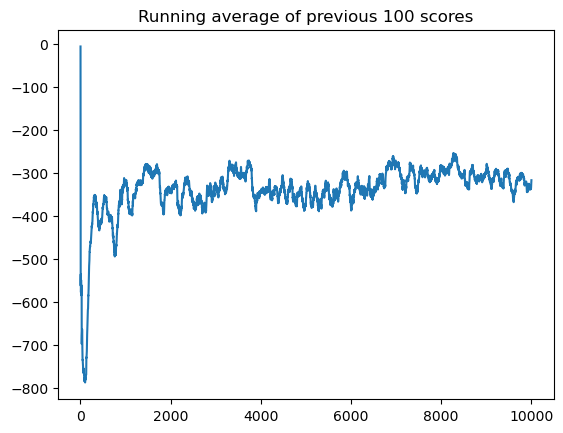

<Figure size 640x480 with 0 Axes>

In [10]:
plot_learning_curve(scores=score_history, x=x, figure_file=figure_file)